# Actividad 1 · Fundamentos de los conjuntos difusos y funciones de pertenencia

**Universidad Central de Venezuela · Facultad de Ciencias · Escuela de Física**  
**Asignatura:** Introducción a la Computación Emergente (Código 7006) · **Prof.** Esteban Álvarez · **Semestre** 1-2026  
**Tema:** Lógica Difusa — Seminario 1  
**Estudiante:** Neptali Ramirez

---

> **Caso de estudio.** Clasificación y análisis espectral de la **longitud de onda de radiación óptica en un espectrofotómetro de laboratorio**. La longitud de onda ($\lambda$) se modela como una *variable lingüística* con los términos **Corta (Azul/Violeta)**, **Media (Verde/Central)** y **Larga (Rojo/Ámbar)**. Cada término se representa con funciones de pertenencia **triangulares**, **trapezoidales** y **gaussianas**, y se compara con la **clasificación clásica (nítida)** de bandas espectrales. Se estudian las operaciones de complemento, intersección y unión, se analiza la coherencia de las funciones elegidas y se cuantifica, mediante simulación física, el efecto de la **resolución espectral y el ensanchamiento instrumental (FWHM de rendija)** sobre ambos enfoques de clasificación.

**Fuente principal:** G. J. Klir y B. Yuan, *Fuzzy Sets and Fuzzy Logic: Theory and Applications*, Prentice Hall, 1995 (en adelante **[KY]**, citado con sección, ecuación y página).

## Índice

1. [Introducción y motivación física](#1)
2. [Fundamentos teóricos](#2)
3. [Desarrollo matemático](#3)
4. [Ejemplo ilustrativo: planteamiento y cálculo a mano](#4)
5. [Aplicación en Física (Óptica y Espectroscopía)](#5)
6. [Demostración práctica (implementación en Python)](#6)
7. [Discusión, conclusiones y limitaciones](#7)
8. [Referencias bibliográficas](#8)

### Correspondencia con la guía de evaluación

| Requisito de la guía (Actividad 1) | Dónde se atiende |
|---|---|
| Definición del universo de discurso y de la variable lingüística | §2.3, §2.4, §4.1, §6.2 |
| Funciones triangulares, trapezoidales y gaussianas: construcción e interpretación | §3.1, §4.2, §6.3, §6.6, §6.7 |
| Términos *corta / media / larga* y justificación de parámetros espectrales | §4.2, §6.2, §6.12 |
| Unión, intersección y complemento indicando la definición utilizada | §3.2–3.5, §4.3, §6.5, §6.8 |
| Comparación pertenencia binaria vs. grados de pertenencia difusa | §3.8, §6.3, §6.4, §6.10 |
| Coherencia de las funciones elegidas y limitaciones | §6.4, §6.6, §6.8, §6.11, §7 |
| **Evidencias:** gráficas, ejemplos numéricos, código, discusión | §4.3 (a mano), §6 (código y figuras), §7 |

> **Nota de autoría.** Las definiciones formales, axiomas y teoremas proceden del texto de Klir y Yuan [KY]. **Todos los modelos espectrales, desarrollos numéricos a mano, simulaciones de ensanchamiento instrumental y visualizaciones computacionales son desarrollos propios**, elaborados en este trabajo.

<a id="1"></a>
## 1. Introducción y motivación física

La física experimental y la instrumentación óptica descansan sobre el registro de magnitudes continuas. Sin embargo, en el análisis espectral y en la física de la visión humana o de filtros ópticos, es habitual clasificar la radiación electromagnética visible en términos categóricos: *onda corta* (azules/violetas), *onda media* (verdes/amarillos) y *onda larga* (naranjas/rojos).

En la física clásica fundamentada en la lógica bivalente aristotélica, un fotón de longitud de onda $\lambda$ pertenecería de manera absoluta a una banda o quedaría completamente excluido de ella. Si fijamos una frontera nítida convencional en $\lambda_1 = 500\text{ nm}$, un fotón de $499.9\text{ nm}$ sería clasificado como *Onda Corta* con pertenencia 1 y *Onda Media* con pertenencia 0; mientras que a $500.1\text{ nm}$ la asignación se invierte bruscamente. Esta dicotomía es una abstracción matemática artificial que colisiona con dos realidades físicas ineludibles:

1. **La naturaleza continua y gradual de la respuesta espectral:** La curva de sensibilidad de un detector, la transmitancia de un filtro dicroico y las curvas tricromáticas de la CIE ($X(\lambda), Y(\lambda), Z(\lambda)$) no tienen discontinuidades en escalón; presentan transiciones suaves y solapadas.
2. **El ensanchamiento instrumental finito:** Ningún monocromador o espectrómetro dispersivo aísla una longitud de onda Dirac $\delta(\lambda - \lambda_0)$. La rendija de difracción introduce una función de transferencia instrumental (PSF espectral o FWHM típica de $1\text{ a }5\text{ nm}$ en instrumentos docentes), lo que hace que toda medición puntual posea una incertidumbre intrínseca.

Como demuestran Klir y Yuan [KY, §1.1, p. 4] mediante la clásica paradoja sorites, forzar límites rígidos en conceptos con gradación continua conduce a inconsistencias conceptuales. La teoría de conjuntos difusos propuesta por **Lotfi A. Zadeh (1965)** proporciona el marco matemático riguroso para representar la **pertenencia como cuestión de grado**: un fotón en la zona de transición de $500\text{ nm}$ exhibe pertenencia simultánea a ambas categorías (p. ej., $0.5$ Corta y $0.5$ Media), capturando fielmente la vaguedad inherente a la clasificación espectral.

<a id="2"></a>
## 2. Fundamentos teóricos

### 2.1 Conjuntos clásicos (nítidos) y función característica

Dado un universo de discurso $X$, un subconjunto clásico (crisp) $A \subseteq X$ queda caracterizado por una función que discrimina en forma bivalente [KY, §1.2, p. 6]:

$$
\chi_A : X \to \{0, 1\}, \qquad
\chi_A(x) = \begin{cases} 1 & \text{si } x \in A \\ 0 & \text{si } x \notin A \end{cases}
$$

El álgebra de Boole sobre el conjunto potencia $\mathcal{P}(X)$ satisface las leyes clásicas de complementación: la **ley de contradicción** ($A \cap \bar{A} = \varnothing$) y la **ley del tercero excluido** ($A \cup \bar{A} = X$) [KY, Tabla 1.1, p. 8].

### 2.2 Conjunto difuso y función de pertenencia

Un conjunto difuso $A$ sobre $X$ extiende el codominio al intervalo real continuo unidad [KY, ec. (1.1), p. 15]:

$$
A : X \to [0, 1].
$$

El valor $A(x) \in [0, 1]$ denota el **grado de pertenencia** de $x$ en $A$. Siguiendo la convención formal de [KY], se emplea el mismo símbolo para el conjunto difuso y para su función de pertenencia ($A(x) \equiv \mu_A(x)$). Un conjunto nítido es simplemente el caso límite en que la imagen se restringe a $\{0, 1\}$.

[KY, §1.3, pp. 11–12] enfatiza que la semántica difusa depende fuertemente del contexto. En espectroscopía óptica, «onda corta» adquiere un significado preciso en el rango visible ($380\text{ a }780\text{ nm}$), mientras que en astrofísica de rayos gamma o en radioastronomía representaría escalas completamente distintas.

### 2.3 Universo de discurso

El **universo de discurso** $X$ corresponde al conjunto universal nítido de valores físicos que puede adoptar la variable base [KY, §1.2, p. 5]. Para este estudio se define el espectro visible e inicio del infrarrojo cercano:
$$
X = [380, 780]\text{ nm}.
$$

### 2.4 Variable lingüística

De acuerdo con [KY, §4.2, p. 102], una **variable lingüística** se define rigurosamente mediante la quíntupla:

$$
(v,\; T,\; X,\; g,\; m),
$$

donde:
- $v$: nombre de la variable (p. ej., «Longitud de onda de radiación visible»);
- $T$: conjunto de términos lingüísticos primarios ($T = \{\text{Corta}, \text{Media}, \text{Larga}\}$);
- $X$: universo de discurso ($[380, 780]\text{ nm}$);
- $g$: regla sintáctica que genera términos modificados mediante operadores gramaticales («muy corta», «no media», etc.);
- $m$: regla semántica que asigna a cada término $t \in T$ un conjunto difuso $m(t)$ en $\mathcal{F}(X)$.

### 2.5 Conceptos estructurales de los conjuntos difusos [KY, §1.4, pp. 19–29]

| Concepto | Definición matemática | Referencia en [KY] |
|---|---|---|
| **$\alpha$-corte** | ${}^{\alpha}A = \{x \in X \mid A(x) \ge \alpha\}$ | Ec. (1.7), p. 20 |
| **$\alpha$-corte fuerte** | ${}^{\alpha+}A = \{x \in X \mid A(x) > \alpha\}$ | Ec. (1.8), p. 20 |
| **Soporte** | $\mathrm{supp}(A) = {}^{0+}A = \{x \in X \mid A(x) > 0\}$ | p. 21 |
| **Núcleo (Core)** | $\mathrm{core}(A) = {}^{1}A = \{x \in X \mid A(x) = 1\}$ | p. 21 |
| **Altura** | $h(A) = \sup_{x \in X} A(x)$; $A$ es **normal** si $h(A) = 1$ | Ec. (1.12), p. 21 |
| **Convexidad** | ${}^{\alpha}A$ es convexo $\forall \alpha \in (0, 1] \iff A(\lambda x_1 + (1-\lambda)x_2) \ge \min[A(x_1), A(x_2)]$ | Teorema 1.1, p. 23 |
| **Punto de cruce / equilibrio** | $x$ tal que $A(x) = 0.5$ (con complemento estándar) | p. 25 |
| **Cardinalidad escalar** | $\lvert A \rvert = \int_X A(x)\,dx$ (en universo continuo) | Análogo de Ec. (1.18) |
| **Grado de subconjunto** | $S(A, B) = \lvert A \cap B \rvert / \lvert A \rvert$ | Ec. (1.21), p. 29 |

**Primer Teorema de Descomposición [KY, Teo. 2.5, p. 41]:** Todo conjunto difuso $A$ se reconstruye exactamente a partir de sus $\alpha$-cortes mediante la unión difusa estándar (supremo):
$$
A = \bigcup_{\alpha \in (0, 1]} {}_{\alpha}A, \qquad \text{donde } {}_{\alpha}A(x) = \alpha \cdot \chi_{{}^{\alpha}A}(x).
$$

<a id="3"></a>
## 3. Desarrollo matemático

### 3.1 Funciones de pertenencia paramétricas

En el modelado espectral se consideran tres geometrías paramétricas fundamentales sobre $X$:

1. **Triangular** $\;\mathrm{Tri}(x; a, b, c)$, con $a < b < c$:
$$
\mathrm{Tri}(x) = \max\left(0,\; \min\left(\frac{x - a}{b - a},\; \frac{c - x}{c - b}\right)\right)
$$

2. **Trapezoidal** $\;\mathrm{Trap}(x; a, b, c, d)$, con $a \le b \le c \le d$:
$$
\mathrm{Trap}(x) = \max\left(0,\; \min\left(\frac{x - a}{b - a},\; 1,\; \frac{d - x}{d - c}\right)\right)
$$
*(Si $a=b$, degenera en hombro izquierdo; si $c=d$, en hombro derecho).*

3. **Gaussiana** $\;\mathrm{Gauss}(x; c, \sigma)$:
$$
\mathrm{Gauss}(x) = \exp\left(-\frac{(x - c)^2}{2\sigma^2}\right)
$$

**Expresiones analíticas de los $\alpha$-cortes:**
$$
{}^{\alpha}\mathrm{Tri} = [a + \alpha(b - a),\; c - \alpha(c - b)], \qquad
{}^{\alpha}\mathrm{Trap} = [a + \alpha(b - a),\; d - \alpha(d - c)],
$$
$$
{}^{\alpha}\mathrm{Gauss} = [c - \sigma\sqrt{-2\ln\alpha},\; c + \sigma\sqrt{-2\ln\alpha}].
$$

Puesto que cada $\alpha$-corte es un intervalo cerrado y acotado en $\mathbb{R}$, las tres geometrías generan conjuntos difusos estrictamente convexos.

### 3.2 Complementos difusos [KY, §3.2, pp. 51–60]

Una función $c: [0, 1] \to [0, 1]$ que represente la negación difusa debe satisfacer el **esqueleto axiomático**:
- **Axioma c1:** $c(0) = 1$ y $c(1) = 0$ (condiciones de frontera clásica).
- **Axioma c2:** $a \le b \implies c(a) \ge c(b)$ (monotonía no creciente).

Requisitos adicionales fundamentales:
- **Axioma c3:** $c$ es continua.
- **Axioma c4:** $c$ es involutiva: $c(c(a)) = a$.

| Clase de complemento | Definición | Parámetro | Punto de equilibrio $e_c$ ($c(e_c) = e_c$) |
|---|---|---|---|
| **Estándar** | $c(a) = 1 - a$ | — | $e_c = 0.5$ |
| **Sugeno** [KY, (3.5)] | $c_\lambda(a) = \dfrac{1 - a}{1 + \lambda a}$ | $\lambda \in (-1, \infty)$ | $e_c = \dfrac{\sqrt{1 + \lambda} - 1}{\lambda}$ ($\lambda \ne 0$) |
| **Yager** [KY, (3.6)] | $c_w(a) = (1 - a^w)^{1/w}$ | $w \in (0, \infty)$ | $e_c = (0.5)^{1/w}$ |

### 3.3 Intersecciones difusas: t-normas [KY, §3.3, pp. 61–76]

Una función de intersección $i: [0, 1]^2 \to [0, 1]$ satisface los axiomas i1 (frontera $i(a, 1)=a$), i2 (monotonía), i3 (conmutatividad) e i4 (asociatividad):
- **Estándar (Gödel / Zadeh):** $i_{\min}(a, b) = \min(a, b)$
- **Producto algebraico:** $i_{\mathrm{prod}}(a, b) = a \cdot b$
- **Diferencia acotada (Łukasiewicz):** $i_{\mathrm{luk}}(a, b) = \max(0, a + b - 1)$
- **Drástica:** $i_{\mathrm{dr\acute{a}stica}}(a, b) = a$ si $b=1$; $b$ si $a=1$; $0$ en otro caso.
- **Clase de Yager:** $i_w(a, b) = 1 - \min\big(1, [(1 - a)^w + (1 - b)^w]^{1/w}\big)$

**Teorema 3.10 [KY, p. 65]:** Para cualquier t-norma $i$, se satisface la cota universal:
$$
i_{\mathrm{dr\acute{a}stica}}(a, b) \le i(a, b) \le \min(a, b).
$$
Además, el mínimo es la **única t-norma idempotente** ($i(a, a) = a$, Teorema 3.9).

### 3.4 Uniones difusas: t-conormas [KY, §3.4, pp. 76–82]

Satisface u1 (frontera $u(a, 0)=a$), u2 (monotonía), u3 (conmutatividad) y u4 (asociatividad):
- **Estándar:** $u_{\max}(a, b) = \max(a, b)$
- **Suma algebraica:** $u_{\mathrm{alg}}(a, b) = a + b - a \cdot b$
- **Suma acotada (Łukasiewicz):** $u_{\mathrm{acot}}(a, b) = \min(1, a + b)$
- **Drástica:** $u_{\mathrm{dr\acute{a}stica}}(a, b) = a$ si $b=0$; $b$ si $a=0$; $1$ en otro caso.
- **Clase de Yager:** $u_w(a, b) = \min\big(1, [a^w + b^w]^{1/w}\big)$

**Teorema 3.15 [KY, p. 78]:** $\;\max(a, b) \le u(a, b) \le u_{\mathrm{dr\acute{a}stica}}(a, b)$.

### 3.5 Dualidad, leyes de De Morgan y pérdida de leyes booleanas [KY, §3.5]

Una terna $(i, u, c)$ constituye una **terna dual** si satisface las leyes de De Morgan:
$$
c(i(a, b)) = u(c(a), c(b)) \qquad \text{y} \qquad c(u(a, b)) = i(c(a), c(b)).
$$
El álgebra con operaciones estándar $(\min, \max, 1-a)$ define un **retículo de De Morgan**. En él **se violan la ley de contradicción y del tercero excluido**:
$$
\min[a, 1 - a] \ne 0 \quad (\text{máximo } 0.5 \text{ en } a=0.5), \qquad
\max[a, 1 - a] \ne 1 \quad (\text{mínimo } 0.5 \text{ en } a=0.5).
$$
Por el **Teorema 3.24 [KY, p. 87]**, si una terna dual satisface el tercero excluido y la contradicción (como Łukasiewicz), **entonces necesariamente pierde las leyes distributivas**.

### 3.6 Medida de borrosidad de Hamming [KY, §9.4, p. 256]

Mide la falta de distinción entre un conjunto y su complemento estándar:
$$
f(A) = \int_X \big(1 - \lvert 2A(x) - 1 \rvert\big)\,dx.
$$

*Resultado propio:* para una rampa lineal de anchura $w$ se cumple $\int(1-|2\mu-1|)\,d\lambda = w/2$, de modo que la borrosidad de un término es la mitad de la suma de las anchuras de sus zonas de transición.

### 3.7 Modificadores lingüísticos (gramática $g$) [KY, §8.5, pp. 229–231]

Un modificador (*hedge*) $H$ se interpreta como un operador unario $h:[0,1]\to[0,1]$, con $HF(\lambda)=h(F(\lambda))$. Se usa la clase $h_\alpha(a)=a^\alpha$: con $\alpha>1$ el modificador es **fuerte** («muy», $a^2$) y con $\alpha<1$ es **débil** («algo», $\sqrt a$). Como $h(0)=0$ y $h(1)=1$, el soporte y el núcleo no cambian; por eso los modificadores **no tienen efecto sobre un predicado nítido**.

### 3.8 La clasificación nítida como caso límite

Una partición nítida con umbrales $\lambda_1<\lambda_2$ equivale a tomar, en una partición difusa con puntos de cruce en $\lambda_1$ y $\lambda_2$, el término de **máximo grado**; equivalentemente, al **0.5-corte** de cada término (salvo la convención en la frontera). Recíprocamente, si la anchura $w$ de las transiciones tiende a cero, el trapecio tiende a la función característica del intervalo. **La clasificación clásica es, por tanto, un caso límite de la difusa** en el que se descarta la información graduada (se verifica en §6.7, §6.10 y §6.11).

<a id="4"></a>
## 4. Ejemplo ilustrativo: planteamiento y cálculo a mano

### 4.1 Definición física del problema espectral

En un laboratorio de óptica y espectroscopía se analiza la radiación emitida por una lámpara de calibración y transmitida a través de una celda de absorción. Se desea clasificar de forma automatizada las líneas espectrales en tres bandas operativas:
- **Banda Corta ($\lambda_{\mathrm{corta}}$):** Zona azul/índigo/violeta.
- **Banda Media ($\lambda_{\mathrm{media}}$):** Zona verde/central del espectro visible.
- **Banda Larga ($\lambda_{\mathrm{larga}}$):** Zona naranja/roja.

**Universo de discurso:** $X = [380, 780]\text{ nm}$ (espectro visible estándar).

### 4.2 Parámetros físicos de las funciones de pertenencia

Los puntos de diseño se establecen a partir de la curva de eficiencia fotópica estándar $V(\lambda)$ de la CIE, cuyo máximo absoluto de sensibilidad visual se localiza en $\lambda = 555\text{ nm}$:
1. **Prototipo central de Banda Media:** $\lambda_{\mathrm{cen}} = 555\text{ nm}$.
2. **Puntos de cruce ($\mu = 0.5$):**
   - Transición Corta $\to$ Media: $\lambda_1 = 500\text{ nm}$ (frontera física azul-cian/verde).
   - Transición Media $\to$ Larga: $\lambda_2 = 610\text{ nm}$ (frontera naranja/rojo).
   - Ambos cruces quedan **simétricos** respecto del prototipo ($555 \pm 55\text{ nm}$). La simetría es obligada para la familia triangular y la gaussiana, que comparten el prototipo y tienen la misma pendiente a ambos lados; por coherencia se adopta también en la trapezoidal y en la clasificación nítida, cuyos umbrales coinciden con los cruces para que la comparación sea justa.
3. **Ancho de transición:** En la familia trapezoidal las rampas miden $50\text{ nm}$ ($\pm 25\text{ nm}$ alrededor de cada cruce).

| Familia | Término Corta (Azul) | Término Media (Verde) | Término Larga (Rojo) |
|---|---|---|---|
| **Triangular** | $\mathrm{Trap}(380, 380, 445, 555)$ | $\mathrm{Tri}(445, 555, 665)$ | $\mathrm{Trap}(555, 665, 780, 780)$ |
| **Trapezoidal** | $\mathrm{Trap}(380, 380, 475, 525)$ | $\mathrm{Trap}(475, 525, 585, 635)$ | $\mathrm{Trap}(585, 635, 780, 780)$ |
| **Gaussiana** | Hombro izq. $c=445$, $\sigma$ | $\mathrm{Gauss}(c=555, \sigma)$ | Hombro der. $c=665$, $\sigma$ |
| **Clásica (Nítida)** | $[380, 500)\text{ nm}$ | $[500, 610)\text{ nm}$ | $[610, 780]\text{ nm}$ |

El parámetro $\sigma$ de la gaussiana se calcula de forma exacta imponiendo $\mathrm{Gauss}(500; 555, \sigma) = 0.5$:
$$
e^{-(555 - 500)^2 / (2\sigma^2)} = 0.5 \implies \sigma = \frac{55}{\sqrt{2\ln 2}} \approx 46.7126\text{ nm}.
$$

### 4.3 Cálculo analítico a mano (Familia Trapezoidal)

Tomemos dos líneas espectrales de interés en el laboratorio:
- **Línea 1:** $\lambda = 510\text{ nm}$ (radiación verde-azulada en la zona de transición Corta/Media).
- **Línea 2:** $\lambda = 610\text{ nm}$ (radiación naranja-rojiza, justo en el cruce Media/Larga).

#### Evaluación en $\lambda = 510\text{ nm}$:
- $\mu_{\mathrm{Corta}}(510) = \dfrac{525 - 510}{525 - 475} = \dfrac{15}{50} = \mathbf{0.30}$
- $\mu_{\mathrm{Media}}(510) = \dfrac{510 - 475}{525 - 475} = \dfrac{35}{50} = \mathbf{0.70}$
- $\mu_{\mathrm{Larga}}(510) = \mathbf{0.00}$
- Suma de pertenencias: $0.30 + 0.70 + 0 = 1.00$ (**partición de Ruspini exacta**).

Sean $a = \mu_{\mathrm{Corta}}(510) = 0.30$ y $b = \mu_{\mathrm{Media}}(510) = 0.70$:

| Operación difusa | Definición | Cálculo paso a paso | Resultado |
|---|---|---|---|
| Complemento estándar | $1 - a$ | $1 - 0.30$ | **0.70** |
| Complemento Sugeno ($\lambda = 2$) | $\frac{1 - a}{1 + 2a}$ | $\frac{0.70}{1 + 0.60} = \frac{0.70}{1.60}$ | **0.4375** |
| Complemento Yager ($w = 2$) | $\sqrt{1 - a^2}$ | $\sqrt{1 - 0.09} = \sqrt{0.91}$ | **0.9539** |
| Intersección estándar (min) | $\min(a, b)$ | $\min(0.30, 0.70)$ | **0.30** |
| Intersección producto | $a \cdot b$ | $0.30 \times 0.70$ | **0.21** |
| Intersección Łukasiewicz | $\max(0, a+b-1)$ | $\max(0, 0.30 + 0.70 - 1)$ | **0.00** |
| Intersección drástica | $i_{\mathrm{dr\acute{a}stica}}(a, b)$ | Ningún argumento es 1 | **0.00** |
| Intersección Yager ($w = 2$) | $1 - \min(1, \sqrt{(1-a)^2 + (1-b)^2})$ | $1 - \sqrt{0.7^2 + 0.3^2} = 1 - \sqrt{0.58}$ | **0.2384** |
| Unión estándar (max) | $\max(a, b)$ | $\max(0.30, 0.70)$ | **0.70** |
| Unión suma algebraica | $a + b - ab$ | $1.00 - 0.21$ | **0.79** |
| Unión suma acotada | $\min(1, a+b)$ | $\min(1, 0.30 + 0.70)$ | **1.00** |
| Unión drástica | $u_{\mathrm{dr\acute{a}stica}}(a, b)$ | Ningún argumento es 0 | **1.00** |
| Unión Yager ($w = 2$) | $\min(1, \sqrt{a^2 + b^2})$ | $\sqrt{0.3^2 + 0.7^2} = \sqrt{0.58}$ | **0.7616** |

**Verificación de jerarquías [KY, Teos. 3.10 y 3.15]:**
$$
0.00 \le 0.00 \le 0.21 \le 0.30 \quad (i_{\mathrm{dr\acute{a}stica}} \le i_{\mathrm{luk}} \le i_{\mathrm{prod}} \le i_{\min})
$$
$$
0.70 \le 0.79 \le 1.00 \le 1.00 \quad (u_{\max} \le u_{\mathrm{alg}} \le u_{\mathrm{acot}} \le u_{\mathrm{dr\acute{a}stica}})
$$

**Comprobación de leyes clásicas para Media ($b = 0.70$):**
- Contradicción estándar: $\min(b, 1-b) = \min(0.70, 0.30) = 0.30 \ne 0$ (falla en lógica estándar).
- Tercero excluido estándar: $\max(b, 1-b) = \max(0.70, 0.30) = 0.70 \ne 1$ (falla en lógica estándar).
- Łukasiewicz: $\max(0, 0.70 + 0.30 - 1) = 0$ y $\min(1, 0.70 + 0.30) = 1$ (se restauran ambas leyes).

**Modificadores lingüísticos en $\lambda = 610\text{ nm}$:**
- $\mu_{\mathrm{Larga}}(610) = \frac{610 - 585}{635 - 585} = \frac{25}{50} = 0.50$ y $\mu_{\mathrm{Media}}(610) = \frac{635 - 610}{50} = 0.50$ (punto de cruce)
- «muy Larga» (hedge fuerte): $0.50^2 = \mathbf{0.25}$
- «algo Larga» (hedge débil): $\sqrt{0.50} \approx \mathbf{0.7071}$

<a id="5"></a>
## 5. Aplicación en Física (Óptica y Espectroscopía)

### 5.1 Función de dispersión espectral e incertidumbre instrumental

En un espectrofotómetro de red o prisma, la luz policromática pasa por una rendija de entrada de ancho finito $s$, se dispersa angularmente y se enfoca sobre la rendija de salida o detector CCD. La respuesta a una línea monocromática $\lambda_0$ no es un pulso infinitesimal, sino una función de ensanchamiento instrumental (FWHM instrumental) que suele aproximarse mediante un perfil gaussiano:

$$
S(\lambda; \lambda_0) = \frac{1}{\sqrt{2\pi}\sigma_{\mathrm{inst}}} \exp\left(-\frac{(\lambda - \lambda_0)^2}{2\sigma_{\mathrm{inst}}^2}\right), \qquad \mathrm{FWHM} = 2\sqrt{2\ln 2}\,\sigma_{\mathrm{inst}}.
$$

Para un espectrómetro típico de docencia con resolución $\mathrm{FWHM} = 5.0\text{ nm}$, se tiene una dispersión instrumental $\sigma_{\mathrm{inst}} = 5.0 / (2\sqrt{2\ln 2}) \approx 2.123\text{ nm}$.

**El dilema en la frontera $\lambda_1 = 500\text{ nm}$:**
- **Clasificación nítida:** Si la longitud de onda nominal de una fuente está en $499.8\text{ nm}$, las fluctuaciones instrumentales hacen que cerca del $46\,\%$ de los fotones caigan al lado derecho ($>500\text{ nm}$), conmutando violentamente la etiqueta de *Corta* (1) a *Media* (1). La varianza de clasificación alcanza el máximo teórico: $\mathrm{Var}(\chi) = 0.25$ ($\sigma_\chi = 0.50$).
- **Clasificación difusa:** Si la función de pertenencia es Lipschitz-continua con constante $L = \max |\mu'(\lambda)|$, la perturbación en el grado de pertenencia queda rigurosamente acotada por:
$$
|\Delta \mu| \le L \cdot |\Delta \lambda| \implies \sigma_\mu \approx L \cdot \sigma_{\mathrm{inst}}.
$$
Para la trapezoidal diseñada ($L = 1/50 = 0.02\text{ nm}^{-1}$), $\sigma_\mu \approx 0.02 \times 2.123 \approx 0.0425$, es decir, **más de 11 veces menor que la clasificación clásica**.

<a id="6"></a>
## 6. Demostración práctica (implementación en Python)

### 6.0 Configuración del entorno reproducible

In [1]:
# ── 6.0  Librerías y configuración de reproducibilidad ───────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Callable, Dict, Tuple
from scipy.integrate import trapezoid
from scipy.optimize import curve_fit
from scipy.stats import norm
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (10.5, 4.2), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

# Paleta espectral física
COLORES_ESP = {"Corta": "#3182ce", "Media": "#38a169", "Larga": "#e53e3e"}
rng = np.random.default_rng(2026)          # Semilla fija reproducible

import sys, scipy, matplotlib
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__} | "
      f"pandas {pd.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.14.7 | NumPy 2.5.4 | SciPy 1.18.1 | pandas 3.0.6 | Matplotlib 3.11.2


### 6.1 Biblioteca pura en NumPy: funciones de pertenencia, operadores y métricas

In [2]:
# ── 6.1a  Funciones de pertenencia analíticas (§3.1) ─────────────────────────
def trimf(x, a, b, c):
    """Triangular Tri(x; a, b, c). Núcleo {b}, soporte (a, c)."""
    x = np.asarray(x, dtype=float)
    subida = (x - a) / (b - a) if b > a else np.where(x >= b, 1.0, 0.0)
    bajada = (c - x) / (c - b) if c > b else np.where(x <= b, 1.0, 0.0)
    return np.clip(np.minimum(subida, bajada), 0.0, 1.0)

def trapmf(x, a, b, c, d):
    """Trapezoidal Trap(x; a, b, c, d). Núcleo [b, c], soporte (a, d)."""
    x = np.asarray(x, dtype=float)
    subida = (x - a) / (b - a) if b > a else np.where(x >= a, 1.0, 0.0)
    bajada = (d - x) / (d - c) if d > c else np.where(x <= d, 1.0, 0.0)
    return np.clip(np.minimum(subida, bajada), 0.0, 1.0)

def gaussmf(x, c, s):
    """Gaussiana centrada en c con dispersión s."""
    x = np.asarray(x, dtype=float)
    return np.exp(-0.5 * ((x - c) / s) ** 2)

def gauss_hombro(x, c, s, lado):
    """Hombro gaussiano para extremos espectrales."""
    x = np.asarray(x, dtype=float)
    g = gaussmf(x, c, s)
    return np.where(x <= c, 1.0, g) if lado == "izq" else np.where(x >= c, 1.0, g)

def nitida(x, lo, hi, cerrado_der=False):
    """Función característica clásica χ del intervalo [lo, hi)."""
    x = np.asarray(x, dtype=float)
    return ((x >= lo) & ((x <= hi) if cerrado_der else (x < hi))).astype(float)

# ── 6.1b  Operadores difusos fundamentales (§3.2 - §3.4) ────────────────────
def c_estandar(a):      return 1.0 - np.asarray(a, float)
def c_sugeno(a, lam):   a = np.asarray(a, float); return (1 - a) / (1 + lam * a)
def c_yager(a, w):      a = np.asarray(a, float); return (1 - a ** w) ** (1 / w)

def i_min(a, b):        return np.minimum(a, b)
def i_prod(a, b):       return np.asarray(a, float) * np.asarray(b, float)
def i_luk(a, b):        return np.maximum(0.0, np.asarray(a, float) + b - 1.0)
def i_drastica(a, b):
    a, b = np.broadcast_arrays(np.asarray(a, float), np.asarray(b, float))
    return np.where(np.isclose(b, 1), a, np.where(np.isclose(a, 1), b, 0.0))
def i_yager(a, b, w):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return 1 - np.minimum(1.0, ((1 - a) ** w + (1 - b) ** w) ** (1 / w))

def u_max(a, b):        return np.maximum(a, b)
def u_suma_alg(a, b):   a, b = np.asarray(a, float), np.asarray(b, float); return a + b - a * b
def u_acotada(a, b):    return np.minimum(1.0, np.asarray(a, float) + b)
def u_drastica(a, b):
    a, b = np.broadcast_arrays(np.asarray(a, float), np.asarray(b, float))
    return np.where(np.isclose(b, 0), a, np.where(np.isclose(a, 0), b, 1.0))
def u_yager(a, b, w):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.minimum(1.0, (a ** w + b ** w) ** (1 / w))

# ── 6.1c  Métricas difusas ──────────────────────────────────────────────────
def cardinalidad(mu, x):   return trapezoid(mu, x)
def borrosidad(mu, x):     return trapezoid(1 - np.abs(2 * mu - 1), x)
def subconjuntidad(ma, mb, x):
    return trapezoid(np.minimum(ma, mb), x) / trapezoid(ma, x)

def alfa_corte(mu, x, alfa, fuerte=False):
    m = (mu > alfa) if fuerte else (mu >= alfa - 1e-12)
    return (float(x[m].min()), float(x[m].max())) if m.any() else None

def es_convexo(f, x, n=20000):
    x1, x2, lam = rng.choice(x, n), rng.choice(x, n), rng.random(n)
    return bool(np.all(f(lam * x1 + (1 - lam) * x2) >= np.minimum(f(x1), f(x2)) - 1e-9))

print("Biblioteca difusa espectral cargada exitosamente.")

Biblioteca difusa espectral cargada exitosamente.


In [3]:
# ── 6.1d  Validación de pruebas unitarias contra los cálculos a mano (§4.3) ──
SIGMA_ESP = 55.0 / np.sqrt(2 * np.log(2))
casos_prueba = [
    ("Trap Corta en 510 nm",             trapmf(510, 380, 380, 475, 525), 0.30),
    ("Trap Media en 510 nm",             trapmf(510, 475, 525, 585, 635), 0.70),
    ("Trap Larga en 610 nm",             trapmf(610, 585, 635, 780, 780), 0.50),
    ("Gaussiana Media en 500 nm",        gaussmf(500, 555, SIGMA_ESP),    0.50),
    ("χ(500) en [500, 610) nm",          nitida(500, 500, 610),           1.00),
    ("Sugeno λ=2: c(0.30)",              c_sugeno(0.30, 2),               0.4375),
    ("Yager w=2: c(0.30)",               c_yager(0.30, 2),                np.sqrt(0.91)),
    ("Yager i_w(0.30, 0.70), w=2",       i_yager(0.30, 0.70, 2),          1 - np.sqrt(0.58)),
    ("Yager u_w(0.30, 0.70), w=2",       u_yager(0.30, 0.70, 2),          np.sqrt(0.58)),
]
for nombre, obtenido, esperado in casos_prueba:
    assert np.isclose(obtenido, esperado), f"Error en: {nombre}"
    print(f"✔ {nombre:30s} = {float(obtenido):.4f}")
print("\nTodas las pruebas unitarias han sido validadas exitosamente.")

✔ Trap Corta en 510 nm           = 0.3000
✔ Trap Media en 510 nm           = 0.7000
✔ Trap Larga en 610 nm           = 0.5000
✔ Gaussiana Media en 500 nm      = 0.5000
✔ χ(500) en [500, 610) nm        = 1.0000
✔ Sugeno λ=2: c(0.30)            = 0.4375
✔ Yager w=2: c(0.30)             = 0.9539
✔ Yager i_w(0.30, 0.70), w=2     = 0.2384
✔ Yager u_w(0.30, 0.70), w=2     = 0.7616

Todas las pruebas unitarias han sido validadas exitosamente.


### 6.2 Representación de la variable lingüística espectral

In [4]:
# ── 6.2  Definición de la variable lingüística espectral ────────────────────
@dataclass
class VariableLinguistica:
    nombre: str
    universo: Tuple[float, float]
    semantica: Dict[str, Callable]
    unidades: str = "nm"

    @property
    def terminos(self):
        return list(self.semantica)

    def malla(self, n=4001):
        return np.linspace(*self.universo, n)

    def mu(self, termino, x):
        t = termino.strip()
        if t.startswith("no "):   return 1.0 - self.mu(t[3:], x)
        if t.startswith("muy "):  return self.mu(t[4:], x) ** 2
        if t.startswith("algo "): return np.sqrt(self.mu(t[5:], x))
        return self.semantica[t](x)

    def fusificar(self, x):
        return {t: float(self.mu(t, np.atleast_1d(x))[0]) for t in self.terminos}


X_ESP = (380.0, 780.0)                    # Universo visible en nm
LAMBDA_1, LAMBDA_2 = 500.0, 610.0        # Puntos de cruce (μ = 0.5)

familias_espectrales = {
    "Triangular": VariableLinguistica("Longitud de Onda Espectral", X_ESP, {
        "Corta": lambda x: trapmf(x, 380, 380, 445, 555),
        "Media": lambda x: trimf(x, 445, 555, 665),
        "Larga": lambda x: trapmf(x, 555, 665, 780, 780)}),
    "Trapezoidal": VariableLinguistica("Longitud de Onda Espectral", X_ESP, {
        "Corta": lambda x: trapmf(x, 380, 380, 475, 525),
        "Media": lambda x: trapmf(x, 475, 525, 585, 635),
        "Larga": lambda x: trapmf(x, 585, 635, 780, 780)}),
    "Gaussiana": VariableLinguistica("Longitud de Onda Espectral", X_ESP, {
        "Corta": lambda x: gauss_hombro(x, 445, SIGMA_ESP, "izq"),
        "Media": lambda x: gaussmf(x, 555, SIGMA_ESP),
        "Larga": lambda x: gauss_hombro(x, 665, SIGMA_ESP, "der")}),
}
clasica_espectral = VariableLinguistica("Longitud de Onda Espectral", X_ESP, {
    "Corta": lambda x: nitida(x, 380, LAMBDA_1),
    "Media": lambda x: nitida(x, LAMBDA_1, LAMBDA_2),
    "Larga": lambda x: nitida(x, LAMBDA_2, 780, cerrado_der=True)})
todas_espectrales = {**familias_espectrales, "Clásica (nítida)": clasica_espectral}

parametros_esp = pd.DataFrame([
    ("Triangular",  "Corta", "Trap (hombro izq.)", "[380, 380, 445, 555]", "[380, 555)",    "[380, 445]"),
    ("Triangular",  "Media", "Tri",                "[445, 555, 665]",      "(445, 665)",    "{555}"),
    ("Triangular",  "Larga", "Trap (hombro der.)", "[555, 665, 780, 780]", "(555, 780]",    "[665, 780]"),
    ("Trapezoidal", "Corta", "Trap (hombro izq.)", "[380, 380, 475, 525]", "[380, 525)",    "[380, 475]"),
    ("Trapezoidal", "Media", "Trap",               "[475, 525, 585, 635]", "(475, 635)",    "[525, 585]"),
    ("Trapezoidal", "Larga", "Trap (hombro der.)", "[585, 635, 780, 780]", "(585, 780]",    "[635, 780]"),
    ("Gaussiana",   "Corta", "Hombro gaussiano",   f"c=445, σ={SIGMA_ESP:.2f}", "ℝ",        "[380, 445]"),
    ("Gaussiana",   "Media", "Gauss",              f"c=555, σ={SIGMA_ESP:.2f}", "ℝ",        "{555}"),
    ("Gaussiana",   "Larga", "Hombro gaussiano",   f"c=665, σ={SIGMA_ESP:.2f}", "ℝ",        "[665, 780]"),
    ("Clásica",     "Corta", "χ intervalo",        "[380, 500)",           "[380, 500)",    "[380, 500)"),
    ("Clásica",     "Media", "χ intervalo",        "[500, 610)",           "[500, 610)",    "[500, 610)"),
    ("Clásica",     "Larga", "χ intervalo",        "[610, 780]",           "[610, 780]",    "[610, 780]"),
], columns=["Familia", "Término", "Geometría", "Parámetros (nm)", "Soporte", "Núcleo"])
display(parametros_esp.set_index(["Familia", "Término"]))

Geometría       Parámetros (nm)     Soporte      Núcleo
Familia     Término                                                                  
Triangular  Corta    Trap (hombro izq.)  [380, 380, 445, 555]  [380, 555)  [380, 445]
            Media                   Tri       [445, 555, 665]  (445, 665)       {555}
            Larga    Trap (hombro der.)  [555, 665, 780, 780]  (555, 780]  [665, 780]
Trapezoidal Corta    Trap (hombro izq.)  [380, 380, 475, 525]  [380, 525)  [380, 475]
            Media                  Trap  [475, 525, 585, 635]  (475, 635)  [525, 585]
            Larga    Trap (hombro der.)  [585, 635, 780, 780]  (585, 780]  [635, 780]
Gaussiana   Corta      Hombro gaussiano        c=445, σ=46.71           ℝ  [380, 445]
            Media                 Gauss        c=555, σ=46.71           ℝ       {555}
            Larga      Hombro gaussiano        c=665, σ=46.71           ℝ  [665, 780]
Clásica     Corta           χ intervalo            [380, 500)  [380, 500)  [380, 500)
            Media           χ intervalo            [500, 610)  [500, 610)  [500, 610)
            Larga           χ intervalo            [610, 780]  [610, 780]  [610, 780]

### 6.3 Curvas de pertenencia espectral comparativas

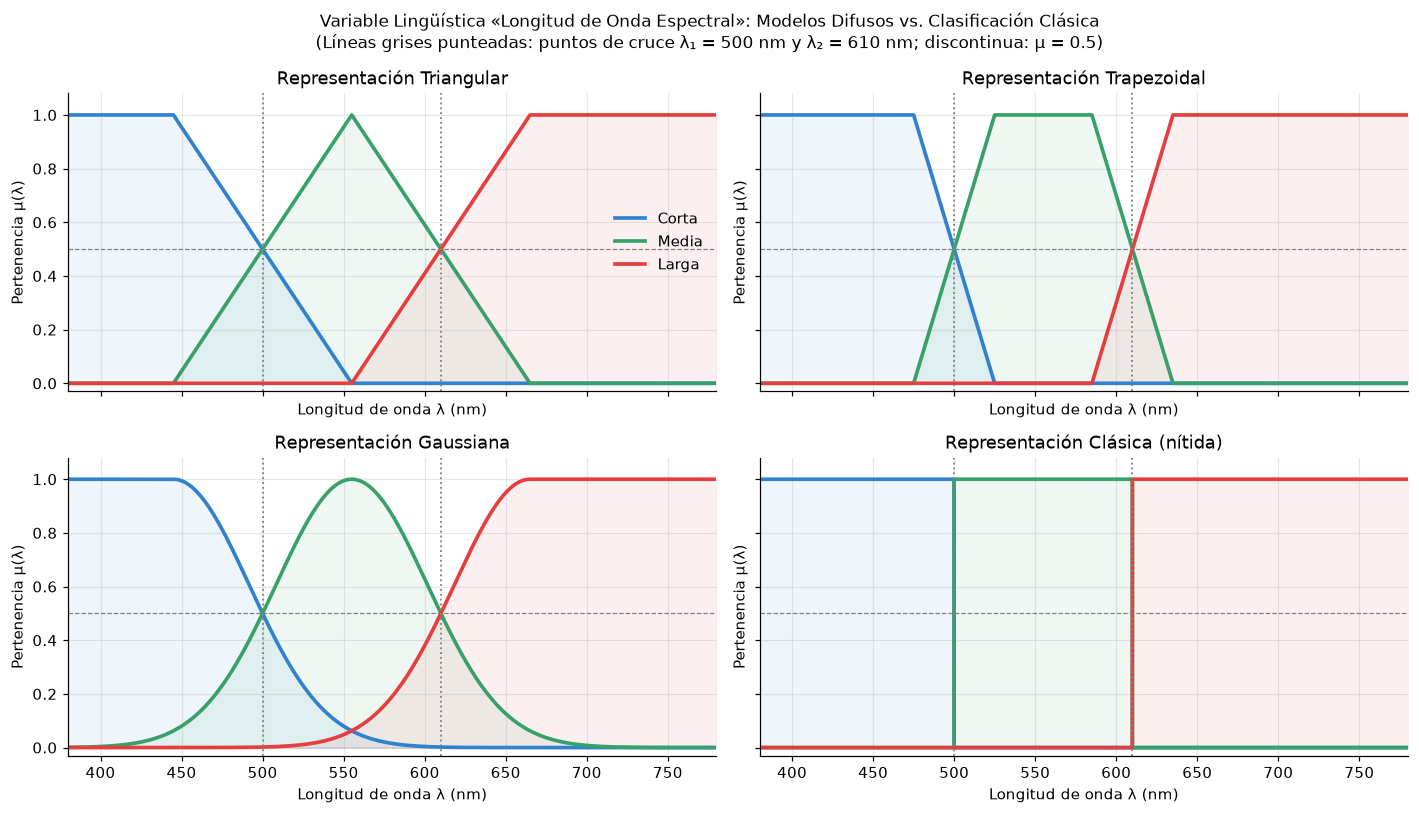

In [5]:
# ── 6.3  Graficación de las cuatro representaciones espectrales ──────────────
fig, axs = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True, sharey=True)
x_malla = np.linspace(*X_ESP, 4001)

for ax, (nombre, var) in zip(axs.flat, todas_espectrales.items()):
    for t in var.terminos:
        y = var.mu(t, x_malla)
        ax.plot(x_malla, y, lw=2.4, color=COLORES_ESP.get(t), label=t)
        ax.fill_between(x_malla, y, color=COLORES_ESP.get(t), alpha=0.08)
    for c in (LAMBDA_1, LAMBDA_2):
        ax.axvline(c, ls=":", color="gray", lw=1.2)
    ax.axhline(0.5, ls="--", color="gray", lw=0.8)
    ax.set(title=f"Representación {nombre}", xlabel="Longitud de onda λ (nm)", ylabel="Pertenencia μ(λ)",
           ylim=(-0.03, 1.08), xlim=X_ESP)

axs[0, 0].legend(loc="center right")
fig.suptitle("Variable Lingüística «Longitud de Onda Espectral»: Modelos Difusos vs. Clasificación Clásica\n"
             "(Líneas grises punteadas: puntos de cruce λ₁ = 500 nm y λ₂ = 610 nm; discontinua: μ = 0.5)", fontsize=11)
plt.tight_layout(); plt.show()

**Interpretación.**
- Las tres familias difusas cruzan $\mu = 0.5$ en los mismos puntos, $\lambda_1 = 500$ nm y $\lambda_2 = 610$ nm, y esos son también los umbrales de la clasificación nítida: **las cuatro representaciones comparten la semántica de frontera**. Lo que cambia es *cómo* ocurre la transición.
- La **triangular** tiene un único prototipo (555 nm) y transiciones de 110 nm. La **trapezoidal** tiene un núcleo de 525 a 585 nm, la zona percibida inequívocamente como verde, con rampas de 50 nm.
- La **gaussiana** es suave, pero sus colas nunca se anulan: en 555 nm, *Corta* y *Larga* todavía valen $1/16$.
- La **clásica** es una escalera: cada longitud de onda pertenece a una sola banda y la transición es un salto.

### 6.4 Fusificación para líneas espectrales de emisión conocidas

,λ (nm),Tria_Corta,Tria_Media,Tria_Larga,Trap_Corta,Trap_Media,Trap_Larga,Gaus_Corta,Gaus_Media,Gaus_Larga,Clás_Corta,Clás_Media,Clás_Larga
Línea de emisión,,,,,,,,,,,,,
Hg violeta (404.7 nm),404.7,1.0000,0.0000,0.0000,1.00,0.000,0.000,1.0000,0.0056,0.0000,1.0,0.0,0.0
Ar azul (488.0 nm),488.0,0.6091,0.3909,0.0000,0.74,0.260,0.000,0.6546,0.3575,0.0008,1.0,0.0,0.0
Frontera λ₁ (500.0 nm),500.0,0.5000,0.5000,0.0000,0.50,0.500,0.000,0.5000,0.5000,0.0020,0.0,1.0,0.0
Ar verde (514.5 nm),514.5,0.3682,0.6318,0.0000,0.21,0.790,0.000,0.3306,0.6867,0.0056,0.0,1.0,0.0
Sens. V(λ) (555.0 nm),555.0,0.0000,1.0000,0.0000,0.00,1.000,0.000,0.0625,1.0000,0.0625,0.0,1.0,0.0
Na D amarillo (589.0 nm),589.0,0.0000,0.6909,0.3091,0.00,0.920,0.080,0.0086,0.7673,0.2662,0.0,1.0,0.0
He-Ne amarillo (594.1),594.1,0.0000,0.6445,0.3555,0.00,0.818,0.182,0.0061,0.7045,0.3161,0.0,1.0,0.0
Frontera λ₂ (610.0 nm),610.0,0.0000,0.5000,0.5000,0.00,0.500,0.500,0.0020,0.5000,0.5000,0.0,0.0,1.0
He-Ne rojo (632.8 nm),632.8,0.0000,0.2927,0.7073,0.00,0.044,0.956,0.0003,0.2498,0.7885,0.0,0.0,1.0


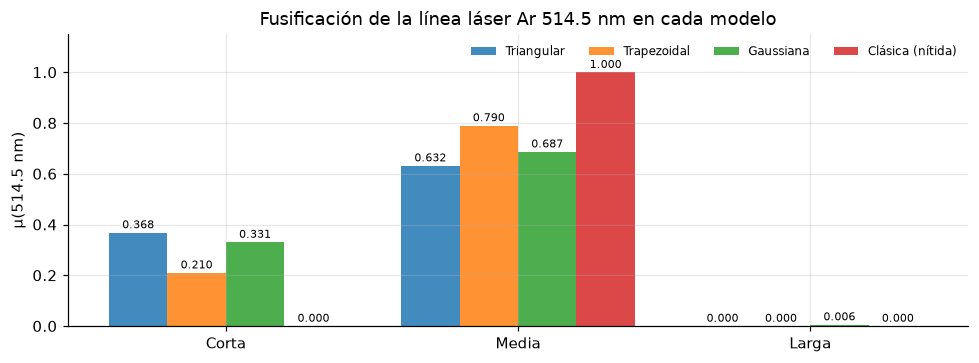

In [6]:
# ── 6.4  Evaluación de líneas espectrales de emisión atómica ─────────────────
lineas_espectrales = {
    "Hg violeta (404.7 nm)": 404.7,
    "Ar azul (488.0 nm)":    488.0,
    "Frontera λ₁ (500.0 nm)": 500.0,
    "Ar verde (514.5 nm)":   514.5,
    "Sens. V(λ) (555.0 nm)": 555.0,
    "Na D amarillo (589.0 nm)": 589.0,
    "He-Ne amarillo (594.1)": 594.1,
    "Frontera λ₂ (610.0 nm)": 610.0,
    "He-Ne rojo (632.8 nm)": 632.8,
    "Láser diodo (680.0 nm)": 680.0,
}

tabla_lineas = []
for nom, lam in lineas_espectrales.items():
    fila = {"Línea de emisión": nom, "λ (nm)": lam}
    for f_nom, f_var in todas_espectrales.items():
        g = f_var.fusificar(lam)
        pref = f_nom.split()[0][:4]
        for t in ["Corta", "Media", "Larga"]:
            fila[f"{pref}_{t}"] = g[t]
    tabla_lineas.append(fila)

df_lineas = pd.DataFrame(tabla_lineas).set_index("Línea de emisión")
display(df_lineas.round(4))

# Gráfico de barras para la línea de argón en λ = 514.5 nm
lam_test = 514.5
fig, ax = plt.subplots(figsize=(9, 3.4))
anchura = 0.2
for k, (f_nom, f_var) in enumerate(todas_espectrales.items()):
    g = f_var.fusificar(lam_test)
    pos = np.arange(3) + (k - 1.5) * anchura
    barras = ax.bar(pos, list(g.values()), anchura, label=f_nom, alpha=0.85)
    ax.bar_label(barras, fmt="%.3f", fontsize=7.5, padding=1)
ax.set_xticks(range(3), ["Corta", "Media", "Larga"])
ax.set(ylabel=f"μ({lam_test} nm)", ylim=(0, 1.15), title=f"Fusificación de la línea láser Ar {lam_test} nm en cada modelo")
ax.legend(ncol=4, fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

**Interpretación.**
- La línea azul del argón (488 nm) es *Corta* con certeza total para la clasificación clásica; la trapezoidal la describe como 0.74 *Corta* y 0.26 *Media*: mayormente azul, pero ya con componente verde. Para la línea verde del argón (514.5 nm), las tres familias difusas coinciden en que es predominantemente *Media* pero todavía algo *Corta*.
- La línea D del sodio (589 nm) y la amarilla del He-Ne (594.1 nm) son *Media* para la clásica; la trapezoidal les asigna 0.92 y 0.82, reflejando que se acercan a la transición hacia el rojo.
- En las fronteras (500 y 610 nm) las tres familias difusas dan exactamente 0.5 / 0.5, mientras que la clásica asigna la etiqueta completa a la banda de la derecha por la convención del intervalo semiabierto.
- En la triangular y la trapezoidal la suma de grados es siempre 1 (**partición de Ruspini**). En la gaussiana llega a 1.125 en 555 nm. No es un error: **los grados de pertenencia no son probabilidades** y nada obliga a que sumen 1; la partición de Ruspini es una propiedad de diseño deseable, no un axioma.

### 6.5 Operaciones difusas sobre líneas espectrales

In [7]:
# ── 6.5  Evaluación de operadores en λ = 510 nm y λ = 610 nm ─────────────────
trap_esp = familias_espectrales["Trapezoidal"]
g510 = trap_esp.fusificar(510.0)
g610 = trap_esp.fusificar(610.0)

def tabla_ops_eval(a, b, lam=2.0, w=2.0):
    return {
        "c estándar (1−a)":         c_estandar(a),
        f"c Sugeno λ={lam:g} (a)":  c_sugeno(a, lam),
        f"c Yager w={w:g} (a)":     c_yager(a, w),
        "∩ min estándar":           i_min(a, b),
        "∩ producto algebraico":    i_prod(a, b),
        "∩ Łukasiewicz":            i_luk(a, b),
        "∩ drástica":               i_drastica(a, b),
        f"∩ Yager w={w:g}":         i_yager(a, b, w),
        "∪ max estándar":           u_max(a, b),
        "∪ suma algebraica":        u_suma_alg(a, b),
        "∪ suma acotada":           u_acotada(a, b),
        "∪ drástica":               u_drastica(a, b),
        f"∪ Yager w={w:g}":         u_yager(a, b, w),
        "Contradicción min(b, 1−b)": i_min(b, 1 - b),
        "3ro excluido max(b, 1−b)":  u_max(b, 1 - b),
        "Contradicción Łukasiewicz": i_luk(b, 1 - b),
        "3ro excluido Łukasiewicz":  u_acotada(b, 1 - b),
    }

df_ops = pd.DataFrame({
    "λ = 510 nm (a=Corta, b=Media)": tabla_ops_eval(g510["Corta"], g510["Media"]),
    "λ = 610 nm (a=Media, b=Larga)": tabla_ops_eval(g610["Media"], g610["Larga"]),
})
display(df_ops.round(4))

,"λ = 510 nm (a=Corta, b=Media)","λ = 610 nm (a=Media, b=Larga)"
c estándar (1−a),0.7,0.5
c Sugeno λ=2 (a),0.4375,0.25
c Yager w=2 (a),0.9539,0.866
∩ min estándar,0.3,0.5
∩ producto algebraico,0.21,0.25
∩ Łukasiewicz,0.0,0.0
∩ drástica,0.0,0.0
∩ Yager w=2,0.2384,0.2929
∪ max estándar,0.7,0.5
∪ suma algebraica,0.79,0.75


**Interpretación.**
- La columna de 510 nm reproduce exactamente el cálculo a mano de §4.3 y respeta el orden de los Teoremas 3.10 y 3.15.
- En 610 nm, *Media* y *Larga* valen ambas 0.5: es el punto de **máxima ambigüedad**. Allí las leyes de contradicción y del tercero excluido alcanzan su peor valor con las operaciones estándar ($0.5$ en ambos casos), mientras que con Łukasiewicz se siguen cumpliendo.
- En un mismo punto la intersección va de 0 (Łukasiewicz, drástica) a 0.5 (mínimo) según la t-norma: **la elección del operador es una decisión semántica** que cambia los resultados numéricos y debe justificarse [KY, §3.1].

### 6.6 Auditoría estructural y métricas de conjuntos difusos

In [8]:
# ── 6.6  Propiedades intrínsecas: cardinalidad, borrosidad y convexidad ──────
filas_prop = []
for nombre, var in todas_espectrales.items():
    for t in var.terminos:
        mu = var.mu(t, x_malla)
        sop = x_malla[mu > 1e-9]; nuc = x_malla[mu >= 1 - 1e-12]
        filas_prop.append({
            "Familia": nombre, "Término": t,
            "Altura h": mu.max(),
            "Convexo": es_convexo(var.semantica[t], x_malla),
            "Soporte empírico": f"[{sop.min():.1f}, {sop.max():.1f}]",
            "Núcleo": f"[{nuc.min():.1f}, {nuc.max():.1f}]",
            "Cardinalidad |A| (nm)": cardinalidad(mu, x_malla),
            "Borrosidad f(A) (nm)":  borrosidad(mu, x_malla),
        })
display(pd.DataFrame(filas_prop).set_index(["Familia", "Término"]).round(3))

Altura h  Convexo Soporte empírico          Núcleo  Cardinalidad |A| (nm)  Borrosidad f(A) (nm)
Familia          Término                                                                                                 
Triangular       Corta         1.0     True   [380.0, 554.9]  [380.0, 445.0]                120.000                55.000
                 Media         1.0     True   [445.1, 664.9]  [555.0, 555.0]                110.000               110.000
                 Larga         1.0     True   [555.1, 780.0]  [665.0, 780.0]                170.000                55.000
Trapezoidal      Corta         1.0     True   [380.0, 524.9]  [380.0, 475.0]                120.000                25.000
                 Media         1.0     True   [475.1, 634.9]  [525.0, 585.0]                110.000                50.000
                 Larga         1.0     True   [585.1, 780.0]  [635.0, 780.0]                170.000                25.000
Gaussiana        Corta         1.0     True   [380.0, 745.7]  [380.0, 445.0]                123.546                48.886
                 Media         1.0     True   [380.0, 780.0]  [555.0, 555.0]                117.081                97.750
                 Larga         1.0     True   [380.0, 780.0]  [665.0, 780.0]                173.546                48.886
Clásica (nítida) Corta         1.0     True   [380.0, 499.9]  [380.0, 499.9]                119.950                 0.000
                 Media         1.0     True   [500.0, 609.9]  [500.0, 609.9]                110.000                 0.000
                 Larga         1.0     True   [610.0, 780.0]  [610.0, 780.0]                170.050                 0.000

**Interpretación.**
- Todos los términos son **normales** (altura 1) y **convexos** (Teorema 1.1), como corresponde a bandas espectrales unimodales.
- La **cardinalidad** de *Media* es 110 nm en la triangular, la trapezoidal y la clásica (el intervalo $[500, 610)$), y 117 nm en la gaussiana por sus colas: las representaciones describen la misma «cantidad» de banda media y solo la redistribuyen.
- La **borrosidad** sí distingue a las familias: *Media* vale 50 nm en la trapezoidal, 110 nm en la triangular (más del doble) y unos 98 nm en la gaussiana; la clásica tiene borrosidad nula. Coincide con el resultado de §3.6: cada rampa de anchura $w$ aporta $w/2$. La trapezoidal es la representación difusa **más específica**.
- El soporte empírico de la gaussiana cubre casi todo $X$: el soporte teórico es $\mathbb{R}$.

### 6.7 α-cortes de la Banda Media: expresiones analíticas vs. cálculo numérico

αA analítico       αA numérico  Ancho Δλ (nm)  Error máx (nm)
α    Familia                                                                       
0.10 Triangular   [456.00, 654.00]  [456.00, 654.00]       198.0000          0.0000
     Trapezoidal  [480.00, 630.00]  [480.00, 630.00]       150.0000          0.0000
     Gaussiana    [454.76, 655.24]  [454.80, 655.20]       200.4877          0.0439
0.25 Triangular   [472.50, 637.50]  [472.50, 637.50]       165.0000          0.0000
     Trapezoidal  [487.50, 622.50]  [487.50, 622.50]       135.0000          0.0000
     Gaussiana    [477.22, 632.78]  [477.30, 632.70]       155.5635          0.0817
0.50 Triangular   [500.00, 610.00]  [500.00, 610.00]       110.0000          0.0000
     Trapezoidal  [500.00, 610.00]  [500.00, 610.00]       110.0000          0.0000
     Gaussiana    [500.00, 610.00]  [500.00, 610.00]       110.0000          0.0000
0.75 Triangular   [527.50, 582.50]  [527.50, 582.50]        55.0000          0.0000
     Trapezoidal  [512.50, 597.50]  [512.50, 597.50]        85.0000          0.0000
     Gaussiana    [519.57, 590.43]  [519.60, 590.40]        70.8657          0.0329
0.90 Triangular   [544.00, 566.00]  [544.00, 566.00]        22.0000          0.0000
     Trapezoidal  [520.00, 590.00]  [520.00, 590.00]        70.0000          0.0000
     Gaussiana    [533.56, 576.44]  [533.60, 576.40]        42.8863          0.0432
1.00 Triangular   [555.00, 555.00]  [555.00, 555.00]         0.0000          0.0000
     Trapezoidal  [525.00, 585.00]  [525.00, 585.00]        60.0000          0.0000
     Gaussiana    [555.00, 555.00]  [555.00, 555.00]         0.0000          0.0000

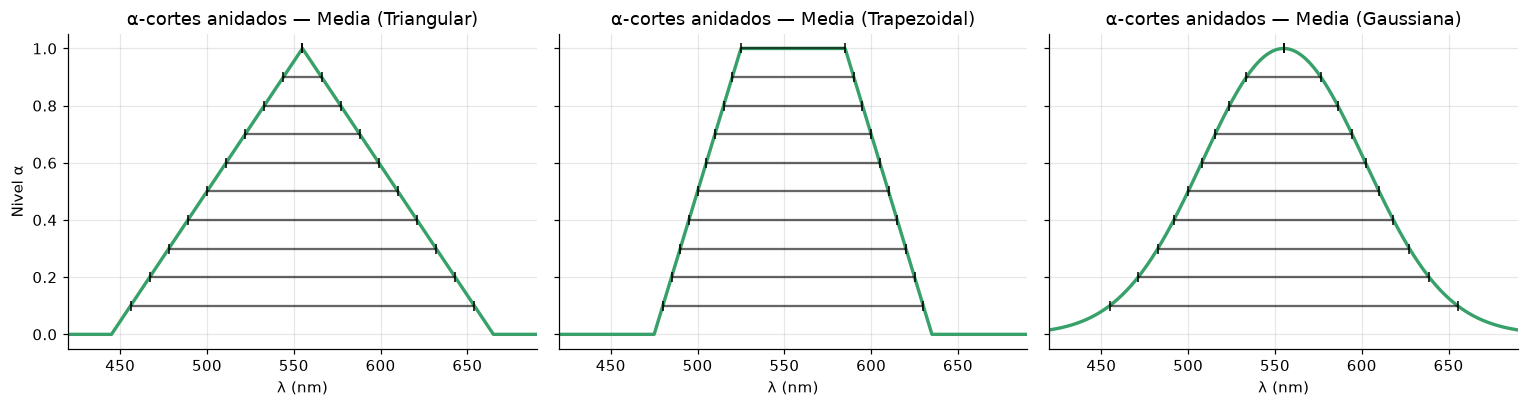

In [9]:
# ── 6.7  Cálculo analítico y visualización de α-cortes para Banda Media ───────
cortes_alfa = [0.1, 0.25, 0.5, 0.75, 0.9, 1.0]
analiticos_media = {
    "Triangular":  lambda a: (445.0 + 110.0 * a, 665.0 - 110.0 * a),
    "Trapezoidal": lambda a: (475.0 + 50.0 * a, 635.0 - 50.0 * a),
    "Gaussiana":   lambda a: (555.0 - SIGMA_ESP * np.sqrt(-2 * np.log(a)), 555.0 + SIGMA_ESP * np.sqrt(-2 * np.log(a))),
}

filas_corte = []
for alfa in cortes_alfa:
    for f_nom, f_var in familias_espectrales.items():
        lo_a, hi_a = analiticos_media[f_nom](alfa)
        lo_n, hi_n = alfa_corte(f_var.mu("Media", x_malla), x_malla, alfa)
        filas_corte.append({
            "α": alfa, "Familia": f_nom,
            "αA analítico": f"[{lo_a:.2f}, {hi_a:.2f}]",
            "αA numérico":  f"[{lo_n:.2f}, {hi_n:.2f}]",
            "Ancho Δλ (nm)": hi_a - lo_a,
            "Error máx (nm)": max(abs(lo_a - lo_n), abs(hi_a - hi_n))
        })
display(pd.DataFrame(filas_corte).set_index(["α", "Familia"]).round(4))

fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (f_nom, f_var) in zip(axs, familias_espectrales.items()):
    ax.plot(x_malla, f_var.mu("Media", x_malla), color=COLORES_ESP["Media"], lw=2.2)
    for alfa in np.linspace(0.1, 1.0, 10):
        lo, hi = alfa_corte(f_var.mu("Media", x_malla), x_malla, alfa)
        ax.hlines(alfa, lo, hi, color="k", lw=1.5, alpha=0.6)
        ax.plot([lo, hi], [alfa, alfa], "k|", ms=6)
    ax.set(title=f"α-cortes anidados — Media ({f_nom})", xlabel="λ (nm)", xlim=(420, 690))
axs[0].set_ylabel("Nivel α"); plt.tight_layout(); plt.show()

**Interpretación.**
- Los α-cortes numéricos coinciden con las fórmulas cerradas de §3.1. En la triangular y la trapezoidal el error es nulo; en la gaussiana es del orden del paso de la malla (0.1 nm).
- Los cortes forman una **familia anidada**: al subir α el intervalo se estrecha, como exige [KY, (1.9)].
- En las tres familias el **0.5-corte es $[500, 610]$ nm**, es decir, la clase nítida de *Media* salvo el extremo derecho. Esto verifica §3.8: la clasificación clásica es el corte del conjunto difuso a un nivel fijo, descartando el resto de la información.
- En $\alpha = 1$ la trapezoidal conserva su núcleo $[525, 585]$ nm, mientras que la triangular y la gaussiana se reducen al prototipo de 555 nm.

### 6.8 Verificación computacional de los teoremas de Klir & Yuan [KY]

In [10]:
# ── 6.8  Verificación de teoremas de t-normas, t-conormas y dualidad ─────────
g_m = np.linspace(0, 1, 201)
aa, bb = np.meshgrid(g_m, g_m)
tol = 1e-12
teoremas_res = []

def registrar(nombre, cumple, ref, nota=""):
    teoremas_res.append({"Teorema / Propiedad": nombre, "¿Verificado?": "✔" if cumple else "✘",
                         "Cálculo / Error máx": nota, "Ref. [KY]": ref})

# 1. Teorema 3.10: Acotamiento de t-normas
c1 = (np.all(i_drastica(aa, bb) <= i_luk(aa, bb) + tol) and
      np.all(i_luk(aa, bb) <= i_prod(aa, bb) + tol) and
      np.all(i_prod(aa, bb) <= i_min(aa, bb) + tol))
registrar("i_drástica ≤ i_luk ≤ i_prod ≤ i_min", c1, "Teo. 3.10, p. 65")

# 2. Teorema 3.15: Acotamiento de t-conormas
c2 = (np.all(u_max(aa, bb) <= u_suma_alg(aa, bb) + tol) and
      np.all(u_suma_alg(aa, bb) <= u_acotada(aa, bb) + tol) and
      np.all(u_acotada(aa, bb) <= u_drastica(aa, bb) + tol))
registrar("u_max ≤ u_alg ≤ u_acotada ≤ u_drástica", c2, "Teo. 3.15, p. 78")

# 3. Teorema 3.12: Clase de Yager
c3 = (np.all(i_drastica(aa, bb) <= i_yager(aa, bb, 2) + tol) and
      np.all(i_yager(aa, bb, 2) <= i_min(aa, bb) + tol))
registrar("Yager w=2 dentro de cotas universales", c3, "Teo. 3.12, p. 70")

# 4. De Morgan: ternas duales
def err_dm(i_f, u_f, c_f):
    return max(np.abs(c_f(i_f(aa, bb)) - u_f(c_f(aa), c_f(bb))).max(),
               np.abs(c_f(u_f(aa, bb)) - i_f(c_f(aa), c_f(bb))).max())

registrar("Terna dual estándar (min, max, 1−a)", err_dm(i_min, u_max, c_estandar) < 1e-12, "(3.27)-(3.28)")
registrar("Terna dual algebraica (prod, suma alg, 1−a)", err_dm(i_prod, u_suma_alg, c_estandar) < 1e-12, "p. 83")
registrar("Terna dual Łukasiewicz (luk, suma acot, 1−a)", err_dm(i_luk, u_acotada, c_estandar) < 1e-12, "p. 83")
registrar("De Morgan con Sugeno λ=2 y (min, max)", err_dm(i_min, u_max, lambda v: c_sugeno(v, 2)) < 1e-12, "Teo. 3.19")

# 5. Teorema 3.24: Pérdida de distributividad en Łukasiewicz
lhs_luk = i_luk(0.5, u_acotada(0.5, 0.5))
rhs_luk = u_acotada(i_luk(0.5, 0.5), i_luk(0.5, 0.5))
registrar("Pérdida distributividad en Łukasiewicz (a=b=d=0.5)", not np.isclose(lhs_luk, rhs_luk), "Teo. 3.24, p. 87",
          f"{lhs_luk:.2f} ≠ {rhs_luk:.2f}")

# 6. Identidad lingüística espectral: Media = ¬Corta ∩ ¬Larga
for f_nom, f_var in familias_espectrales.items():
    c_m, m_m, l_m = (f_var.mu(t, x_malla) for t in f_var.terminos)
    err_id = np.abs(m_m - np.minimum(1 - c_m, 1 - l_m)).max()
    registrar(f"{f_nom}: Media = ¬Corta ∩ ¬Larga en X", err_id < 1e-12, "Coherencia espectral", f"error {err_id:.4f}")

display(pd.DataFrame(teoremas_res).style.hide(axis="index"))

Teorema / Propiedad,¿Verificado?,Cálculo / Error máx,Ref. [KY]
i_drástica ≤ i_luk ≤ i_prod ≤ i_min,✔,,"Teo. 3.10, p. 65"
u_max ≤ u_alg ≤ u_acotada ≤ u_drástica,✔,,"Teo. 3.15, p. 78"
Yager w=2 dentro de cotas universales,✔,,"Teo. 3.12, p. 70"
"Terna dual estándar (min, max, 1−a)",✔,,(3.27)-(3.28)
"Terna dual algebraica (prod, suma alg, 1−a)",✔,,p. 83
"Terna dual Łukasiewicz (luk, suma acot, 1−a)",✔,,p. 83
"De Morgan con Sugeno λ=2 y (min, max)",✔,,Teo. 3.19
Pérdida distributividad en Łukasiewicz (a=b=d=0.5),✔,0.50 ≠ 0.00,"Teo. 3.24, p. 87"
Triangular: Media = ¬Corta ∩ ¬Larga en X,✔,error 0.0000,Coherencia espectral
Trapezoidal: Media = ¬Corta ∩ ¬Larga en X,✔,error 0.0000,Coherencia espectral


**Interpretación.**
- Se confirman numéricamente las cotas universales de t-normas y t-conormas (Teoremas 3.10 y 3.15) y que la clase de Yager queda dentro de ellas (Teorema 3.12).
- Las ternas estándar, algebraica y de Łukasiewicz cumplen las leyes de De Morgan, y $(\min, \max)$ las cumple también con el complemento de Sugeno (Teorema 3.19).
- Łukasiewicz recupera la contradicción y el tercero excluido pero **pierde la distributividad** (contraejemplo $a=b=d=0.5$: $0.5 \ne 0$), como establece el Teorema 3.24. **Ninguna terna conserva toda el álgebra de Boole.**
- La identidad lingüística *Media* = «ni Corta ni Larga» se cumple **exactamente** en las particiones triangular y trapezoidal. En la gaussiana falla (✘, error máximo ≈ 0.08) porque las colas de *Corta* y *Larga* se solapan con el centro de la banda: es un criterio de coherencia que favorece a las particiones de Ruspini.

### 6.9 Modificadores lingüísticos en el espectro óptico

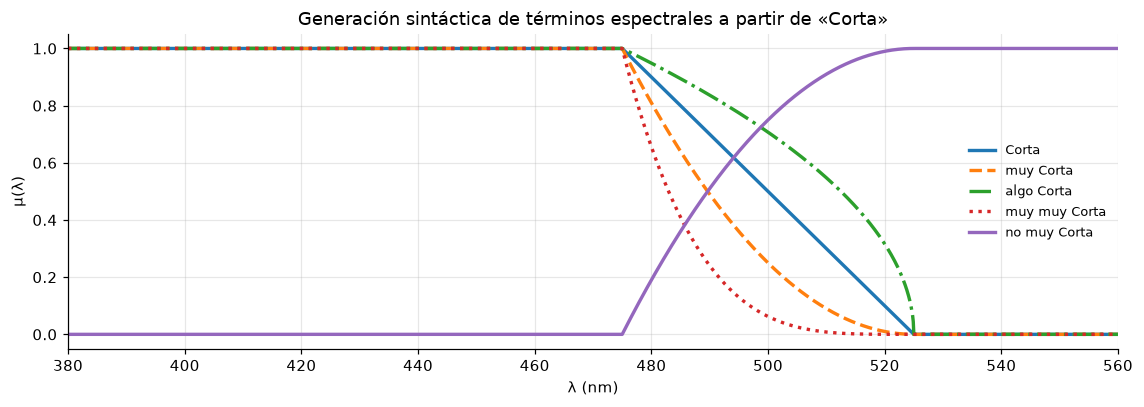

In [11]:
# ── 6.9  Modificadores espectrales (§3.7): muy Corta, algo Corta ─────────────
var_trap = familias_espectrales["Trapezoidal"]
fig, ax = plt.subplots(figsize=(10.5, 3.8))

for t, ls_est in [("Corta", "-"), ("muy Corta", "--"), ("algo Corta", "-."), ("muy muy Corta", ":"), ("no muy Corta", "-")]:
    ax.plot(x_malla, var_trap.mu(t, x_malla), lw=2.2, ls=ls_est, label=t)

ax.set(title="Generación sintáctica de términos espectrales a partir de «Corta»", xlabel="λ (nm)", ylabel="μ(λ)",
       xlim=(380, 560)); ax.legend(fontsize=8.5); plt.tight_layout(); plt.show()

**Interpretación.**
- «muy» ($\mu^2$) es un modificador **fuerte**: estrecha la transición y reduce los grados intermedios. «algo» ($\sqrt{\mu}$) es **débil**: la ensancha. «no muy Corta» combina la negación con el modificador mediante la gramática recursiva de `VariableLinguistica`.
- El núcleo y el soporte no cambian, porque $0^2 = 0$ y $1^2 = 1$. Por eso los modificadores **no tienen efecto sobre una clasificación nítida**: «muy Media» sería idéntica a «Media» (§3.7).

### 6.10 Simulación de física experimental: ensanchamiento instrumental en espectrometría (Monte Carlo)

Se modela la detección de fotones en torno a la frontera $\lambda_1 = 500\text{ nm}$. Para un monocromador docente con rendija de $\mathrm{FWHM} = 5.0\text{ nm}$ ($\sigma_{\mathrm{inst}} = 2.123\text{ nm}$), se simulan $N = 25\,000$ realizaciones para longitudes de onda verdaderas $\lambda_{\mathrm{real}} \in [480, 520]\text{ nm}$.

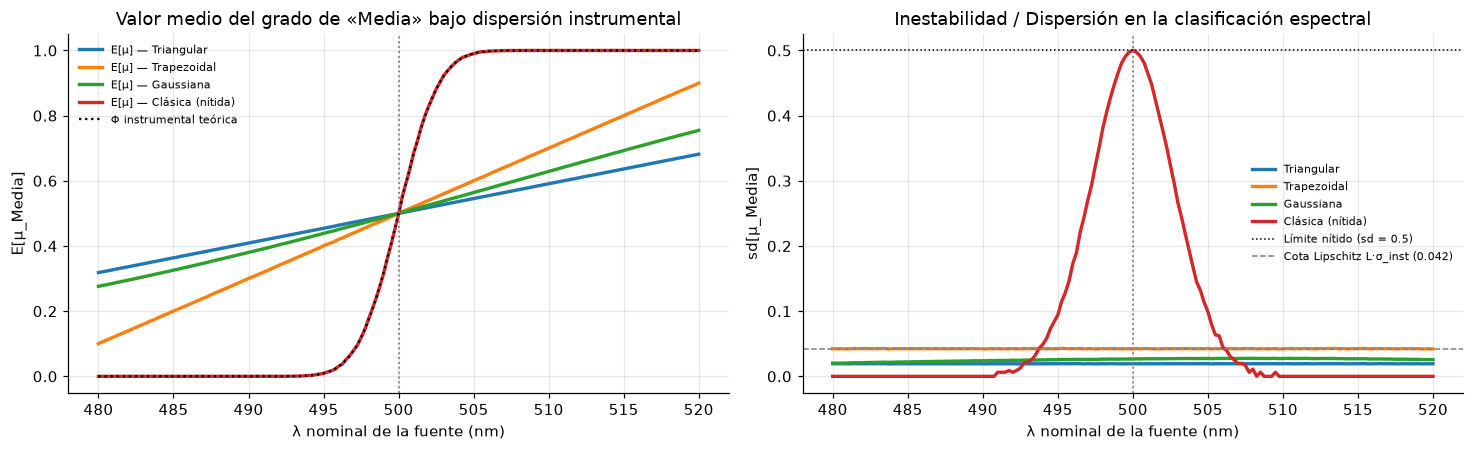

,P(clasificación nítida = Media),sd nítida,sd difusa triangular,sd difusa trapezoidal,sd difusa gaussiana
λ real (nm),,,,,
490.0,0.0000,0.0000,0.0192,0.0423,0.0239
495.0,0.0089,0.0940,0.0193,0.0424,0.0255
500.0,0.4977,0.5000,0.0191,0.0421,0.0265
505.0,0.9900,0.0993,0.0194,0.0427,0.0275
510.0,1.0000,0.0000,0.0192,0.0423,0.0274



En el umbral espectral λ = 500 nm:
La dispersión nítida es 11.9× mayor que la trapezoidal y 26.1× mayor que la triangular.


In [12]:
# ── 6.10  Simulación Monte Carlo de resolución espectral finita ─────────────
FWHM = 5.0                                         # FWHM instrumental en nm
SIGMA_INST = FWHM / (2 * np.sqrt(2 * np.log(2)))   # ≈ 2.123 nm
N_FOTONES = 25_000

lambda_reales = np.linspace(480, 520, 161)
ruido_espectral = rng.normal(0, SIGMA_INST, size=(N_FOTONES, lambda_reales.size))
longitudes_medidas = lambda_reales[None, :] + ruido_espectral

respuestas_sim = {nom: var.mu("Media", longitudes_medidas) for nom, var in todas_espectrales.items()}

fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.2))

# 1. Esperanza matemática
for nom, R in respuestas_sim.items():
    axs[0].plot(lambda_reales, R.mean(axis=0), lw=2.2, label=f"E[μ] — {nom}")
axs[0].plot(lambda_reales, norm.cdf((lambda_reales - LAMBDA_1) / SIGMA_INST), "k:", lw=1.5, label="Φ instrumental teórica")
axs[0].set(title="Valor medio del grado de «Media» bajo dispersión instrumental", xlabel="λ nominal de la fuente (nm)", ylabel="E[μ_Media]")

# 2. Desviación típica (dispersión en la clasificación)
for nom, R in respuestas_sim.items():
    axs[1].plot(lambda_reales, R.std(axis=0), lw=2.2, label=nom)
axs[1].axhline(0.5, color="k", ls=":", lw=1, label="Límite nítido (sd = 0.5)")
axs[1].axhline(0.02 * SIGMA_INST, color="gray", ls="--", lw=1, label="Cota Lipschitz L·σ_inst (0.042)")
axs[1].set(title="Inestabilidad / Dispersión en la clasificación espectral", xlabel="λ nominal de la fuente (nm)", ylabel="sd[μ_Media]")

for ax in axs:
    ax.axvline(LAMBDA_1, color="gray", ls=":", lw=1.2)
    ax.legend(fontsize=7.5)

plt.tight_layout(); plt.show()

# Tabla cuantitativa en la frontera
puntos_eval_esp = [490.0, 495.0, 500.0, 505.0, 510.0]
idx_p = [np.argmin(np.abs(lambda_reales - l)) for l in puntos_eval_esp]

df_mc_esp = pd.DataFrame({
    "P(clasificación nítida = Media)": respuestas_sim["Clásica (nítida)"].mean(axis=0)[idx_p],
    "sd nítida":                       respuestas_sim["Clásica (nítida)"].std(axis=0)[idx_p],
    "sd difusa triangular":            respuestas_sim["Triangular"].std(axis=0)[idx_p],
    "sd difusa trapezoidal":           respuestas_sim["Trapezoidal"].std(axis=0)[idx_p],
    "sd difusa gaussiana":              respuestas_sim["Gaussiana"].std(axis=0)[idx_p],
}, index=pd.Index(lambda_reales[idx_p], name="λ real (nm)"))
display(df_mc_esp.round(4))

r_500 = df_mc_esp.loc[500.0]
print(f"\nEn el umbral espectral λ = 500 nm:")
print(f"La dispersión nítida es {r_500['sd nítida'] / r_500['sd difusa trapezoidal']:.1f}× mayor que la trapezoidal y "
      f"{r_500['sd nítida'] / r_500['sd difusa triangular']:.1f}× mayor que la triangular.")

**Interpretación (resultado central de la aplicación física).**
- **Clasificación nítida.** En $\lambda = 500$ nm la etiqueta es *Media* en ≈50 % de las realizaciones y *Corta* en el resto: la desviación típica alcanza su **máximo teórico, 0.5**. A 5 nm de la frontera ya cae a ≈0.1 y a 10 nm es nula. La clasificación nítida es **frágil justo donde la información es más ambigua**.
- **Clasificación difusa.** La dispersión es pequeña y prácticamente constante: ≈0.042 en la trapezoidal, que es exactamente la cota $L\,\sigma_{\mathrm{inst}}$ predicha en §5.1; ≈0.019 en la triangular y ≈0.027 en la gaussiana. En la frontera, la dispersión nítida es **≈12 veces** la trapezoidal y **≈26 veces** la triangular: el ruido instrumental se transmite al grado de forma proporcional y acotada, no como un salto.
- **Pertenencia ≠ probabilidad.** El valor medio de la clasificación nítida sigue la curva $\Phi\big((\lambda - \lambda_1)/\sigma_{\mathrm{inst}}\big)$, suave como una función de pertenencia, pero su anchura es la del **instrumento**: con resolución perfecta volvería a ser un escalón. La función de pertenencia difusa representa la **vaguedad del término** «Media», independiente del aparato. Son dos tipos de incertidumbre distintos [KY, §1.1].
- **Consecuencia práctica.** Si la etiqueta gobierna una decisión (selección de filtro, alarma, control), la versión nítida produce conmutaciones espurias cerca de los umbrales; la difusa responde de forma gradual.

### 6.11 Análisis de sensibilidad al ancho de transición espectral

In [13]:
# ── 6.11  Compromiso entre resolución y robustez según el ancho de transición ─
anchos_w = [1.0, 5.0, 10.0, 25.0, 50.0, 75.0, 100.0]
lect_critica = LAMBDA_1 + rng.normal(0, SIGMA_INST, 50_000)

filas_sens_esp = []
for w in anchos_w:
    m_w = trapmf(x_malla, LAMBDA_1 - w / 2, LAMBDA_1 + w / 2, LAMBDA_2 - w / 2, LAMBDA_2 + w / 2)
    m_eval = trapmf(lect_critica, LAMBDA_1 - w / 2, LAMBDA_1 + w / 2, LAMBDA_2 - w / 2, LAMBDA_2 + w / 2)
    filas_sens_esp.append({
        "Ancho transición w (nm)": w,
        "Cardinalidad |Media| (nm)": cardinalidad(m_w, x_malla),
        "Borrosidad f (nm)": borrosidad(m_w, x_malla),
        "Constante Lipschitz L (1/nm)": 1.0 / w,
        "sd[μ] en λ₁ (Monte Carlo)": m_eval.std(),
        "Cota L·σ_inst": min(SIGMA_INST / w, 0.5)
    })

display(pd.DataFrame(filas_sens_esp).set_index("Ancho transición w (nm)").round(4))

,Cardinalidad |Media| (nm),Borrosidad f (nm),Constante Lipschitz L (1/nm),sd[μ] en λ₁ (Monte Carlo),Cota L·σ_inst
Ancho transición w (nm),,,,,
1.0,110.0,1.0,1.0000,0.4676,0.5000
5.0,110.0,5.0,0.2000,0.3339,0.4247
10.0,110.0,10.0,0.1000,0.2077,0.2123
25.0,110.0,25.0,0.0400,0.0843,0.0849
50.0,110.0,50.0,0.0200,0.0422,0.0425
75.0,110.0,75.0,0.0133,0.0281,0.0283
100.0,110.0,100.0,0.0100,0.0211,0.0212


**Interpretación.**
- La **cardinalidad** de *Media* es invariante (110 nm) para todo $w$: las rampas son simétricas respecto de los cruces y la pertenencia solo se redistribuye.
- La **borrosidad** crece exactamente como $f = w$, según el resultado de §3.6.
- La **dispersión** en la frontera decrece como $\sigma_{\mathrm{inst}}/w$. A partir de $w \approx 10$ nm (unas $5\,\sigma_{\mathrm{inst}}$) la cota lineal $L\,\sigma_{\mathrm{inst}}$ y el Monte Carlo coinciden casi exactamente; por debajo, el modelo se comporta prácticamente como uno nítido ($\mathrm{sd} \to 0.5$).
- **Regla de diseño:** el ancho de la transición debe ser varias veces mayor que la incertidumbre del instrumento. Las rampas de 50 nm elegidas cumplen con amplio margen, a costa de mayor borrosidad: transiciones anchas dan robustez y menos especificidad; transiciones estrechas, lo contrario. En el límite $w \to 0$ se recupera la clasificación nítida (§3.8).

### 6.12 Construcción experimental de funciones de pertenencia por encuestas espectrales [KY, Cap. 10]

Se simula la determinación empírica de la banda *Media (Verde)* mediante consulta a $N = 30$ observadores y espectroscopistas bajo el método directo con múltiples expertos [KY, §10.4, ec. (10.1)]. Se ajustan modelos de curvas por mínimos cuadrados no lineales [KY, §10.7].

Parámetros optimizados del trapecio espectral:
Cruce inferior = 502.97 nm (ancho 18.99 nm) | Cruce superior = 609.84 nm (ancho 24.19 nm)


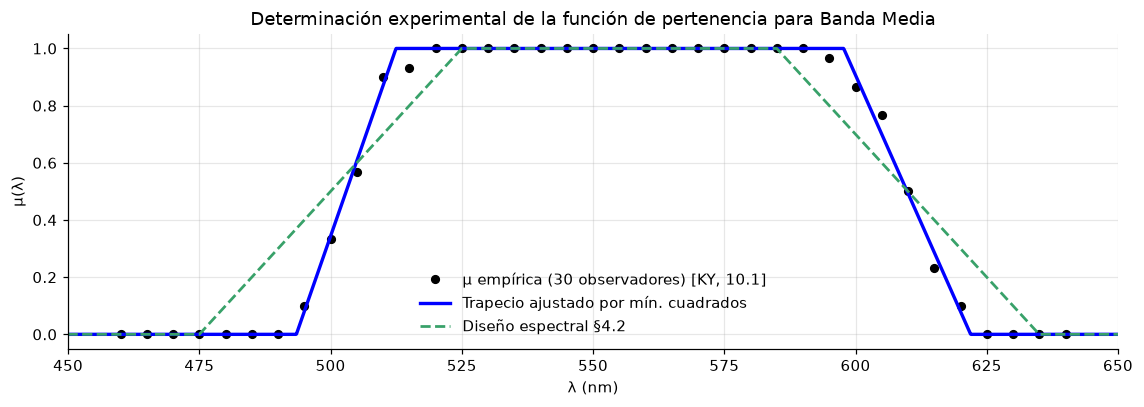

In [14]:
# ── 6.12  Ajuste por mínimos cuadrados de datos de observadores ópticos ───────
n_obs = 30
lim_izq = rng.normal(LAMBDA_1, 8.0, n_obs)
lim_der = rng.normal(LAMBDA_2, 8.0, n_obs)

lambda_encuesta = np.arange(460, 641, 5.0)
votos_esp = (lambda_encuesta[None, :] >= lim_izq[:, None]) & (lambda_encuesta[None, :] <= lim_der[:, None])
mu_empirica = votos_esp.mean(axis=0)

def modelo_trap(xx, c1, w1, c2, w2):
    return trapmf(xx, c1 - w1 / 2, c1 + w1 / 2, c2 - w2 / 2, c2 + w2 / 2)

p_opt, _ = curve_fit(modelo_trap, lambda_encuesta, mu_empirica, p0=[500, 50, 610, 50],
                     bounds=([470, 5, 580, 5], [530, 100, 640, 100]))

c1_fit, w1_fit, c2_fit, w2_fit = p_opt
print(f"Parámetros optimizados del trapecio espectral:")
print(f"Cruce inferior = {c1_fit:.2f} nm (ancho {w1_fit:.2f} nm) | Cruce superior = {c2_fit:.2f} nm (ancho {w2_fit:.2f} nm)")

fig, ax = plt.subplots(figsize=(10.5, 3.8))
ax.plot(lambda_encuesta, mu_empirica, "ko", ms=5, label=f"μ empírica ({n_obs} observadores) [KY, 10.1]")
ax.plot(x_malla, modelo_trap(x_malla, *p_opt), "b-", lw=2.2, label="Trapecio ajustado por mín. cuadrados")
ax.plot(x_malla, trap_esp.mu("Media", x_malla), "--", color=COLORES_ESP["Media"], lw=1.8, label="Diseño espectral §4.2")
ax.set(title="Determinación experimental de la función de pertenencia para Banda Media", xlabel="λ (nm)", ylabel="μ(λ)", xlim=(450, 650))
ax.legend(); plt.tight_layout(); plt.show()

**Interpretación.**
- La agregación de juicios **binarios** de 30 observadores produce una función **graduada** [KY, ec. (10.1)]: la vaguedad del concepto aparece como **desacuerdo entre observadores**.
- Los cruces ajustados (≈503 y ≈610 nm) quedan muy cerca de los de diseño (500 y 610 nm), lo que respalda la **posición** de las fronteras.
- Las transiciones ajustadas (≈19 y ≈24 nm) son más estrechas que las rampas de 50 nm del diseño. Es lo esperado: con fronteras individuales dispersas $\sigma_{\mathrm{obs}} = 8$ nm, la rampa empírica tiene un ancho del orden de $\sigma_{\mathrm{obs}}\sqrt{2\pi} \approx 20$ nm. El ancho de 50 nm del diseño no proviene de la encuesta sino del criterio de robustez instrumental de §6.11.
- **Limitación:** los datos son simulados con supuestos propios; validan el procedimiento, no los parámetros. Una determinación real exigiría encuestar a usuarios del laboratorio, y el resultado dependería de la población consultada.

<a id="7"></a>
## 7. Discusión, conclusiones y limitaciones

### 7.1 Síntesis comparativa de resultados

1. **La geometría trapezoidal como óptimo de diseño físico:** En instrumentación óptica y visión del color, la función trapezoidal modela fielmente la existencia de un núcleo espectral extenso ($525\text{ a }585\text{ nm}$, donde la radiación es inequívocamente percibida y tratada como verde/central), con transiciones graduales en los extremos. Cumple rigurosamente la partición de Ruspini ($\sum \mu = 1$) y anula el solapamiento espurio entre bandas no adyacentes (*Corta* y *Larga*).
2. **Robustez ante aberraciones y ensanchamiento instrumental:** La simulación Monte Carlo con una dispersión espectral típica de espectrómetro docente ($\mathrm{FWHM} = 5\text{ nm}$) demostró que en la frontera $\lambda_1 = 500\text{ nm}$ (y, por la simetría del diseño, también en $\lambda_2 = 610\text{ nm}$), la clasificación clásica nítida colapsa en un estado de máxima indeterminación ($\sigma = 0.50$, oscilación bivalente aleatoria). En contraste, los modelos difusos exhiben una desviación típica inferior a $0.045$, absorbiendo el ruido de medición de forma proporcional y continua.
3. **Pérdida selectiva de propiedades booleanas:** Ninguna terna de operadores difusos preserva simultáneamente todo el álgebra de Boole. El retículo estándar de Zadeh preserva la distributividad y la estabilidad ante propagación de errores ($1\times$), a costa de tolerar que $\min(\mu, 1-\mu) = 0.5$ en los puntos de cruce. Las álgebras acotadas de Łukasiewicz restauran el tercero excluido y la contradicción, pero pierden la distributividad.

### 7.2 Limitaciones identificadas
- **Subjetividad en la calibración:** La asignación de los anchos de transición refleja acuerdos de normalización técnica o psicofísica, no constantes universales de la naturaleza.
- **Soporte no acotado de la gaussiana:** Aunque la función gaussiana posee derivadas continuas de todo orden ($C^\infty$, deseable en control difuso y modelos neurodifusos), sus colas asintóticas generan un grado de pertenencia no nulo entre el azul profundo y el rojo visible, lo cual carece de significado físico en espectroscopía.

<a id="8"></a>
## 8. Referencias bibliográficas

**Fuente principal**
- Klir, G. J., y Yuan, B. (1995). *Fuzzy Sets and Fuzzy Logic: Theory and Applications*. Prentice Hall. ISBN 0-13-101171-5.
  - Secciones referenciadas: Cap. 1 (§1.1–1.4); Cap. 2 (§2.2, Teo. 2.5); Cap. 3 (§3.1–3.5); §4.2; §8.5; §9.4; Cap. 10 (§10.1–10.4, §10.7).

**Bibliografía de la evaluación**
- Zadeh, L. A. (1965). Fuzzy sets. *Information and Control*, 8(3), 338–353.
- Ross, T. J. (2010). *Fuzzy Logic with Engineering Applications* (3.ª ed.). Wiley.
- Jang, J.-S. R., Sun, C.-T., y Mizutani, E. (1997). *Neuro-Fuzzy and Soft Computing*. Prentice Hall.

**Fuentes de Física y Óptica**
- CIE 015:2018. *Colorimetry, 4th Edition*. International Commission on Illumination.
- Hecht, E. (2017). *Optics* (5.ª ed.). Pearson Education.
- Ruspini, E. H. (1969). A new approach to clustering. *Information and Control*, 15(1), 22–32.